Installing NumPy package

In [ ]:
!pip install numpy

Installing FuzzyWuzzy package

In [ ]:
!pip install fuzzywuzzy

Installing TensorFlow package

In [ ]:
!pip install tensorflow

Installing Transformers Package

In [ ]:
!pip install transformers

Installing OpenAI package

In [ ]:
!pip install openai

Installing torch package

In [ ]:
!pip install torch

Installing TextBlob package

In [ ]:
!pip install textblob

Installing Pandas package

> Προσθήκη blockquote



In [ ]:
!pip install pandas

Installing MatplotLib package

In [ ]:
!pip install matplotlib

Installing WordCloud package

In [ ]:
!pip install wordcloud

Importing the libraries

In [ ]:
#Importing the libraries
from openai import OpenAI
import pandas as pd
import fuzzywuzzy
from fuzzywuzzy import fuzz

/usr/local/lib/python3.10/dist-packages/fuzzywuzzy/fuzz.py:11: UserWarning: Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning
  warnings.warn('Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning')


Initializing OpenAI client with API key

In [ ]:
# Initialize the OpenAI client with the API key (read from environment)
import os
api_key = os.getenv('OPENAI_API_KEY')
if not api_key:
    raise ValueError('OPENAI_API_KEY is not set. Set it in your environment (or skip OpenAI cells).')

client = OpenAI(api_key=api_key)


Defining the file paths

In [ ]:
# Define the file paths (use raw strings to avoid issues with backslashes)
file_path_alexa = r'amazon_alexa.tsv'
file_path_amazon = r'data_amazon.csv'

In [ ]:
# Read the TSV (Alexa review data) file with 'ISO-8859-1' encoding to avoid Unicode issues
df_alexa = pd.read_csv(file_path_alexa, sep='\t', encoding='ISO-8859-1')

In [ ]:
df_alexa = df_alexa.head(50)

In [ ]:
# View the first 50 rows of the Alexa review dataset
print(df_alexa.head(50))

    rating       date             variation  \
0        5  31-Jul-18      Charcoal Fabric    
1        5  31-Jul-18      Charcoal Fabric    
2        4  31-Jul-18        Walnut Finish    
3        5  31-Jul-18      Charcoal Fabric    
4        5  31-Jul-18      Charcoal Fabric    
5        5  31-Jul-18  Heather Gray Fabric    
6        3  31-Jul-18     Sandstone Fabric    
7        5  31-Jul-18      Charcoal Fabric    
8        5  30-Jul-18  Heather Gray Fabric    
9        5  30-Jul-18  Heather Gray Fabric    
10       5  30-Jul-18      Charcoal Fabric    
11       5  30-Jul-18      Charcoal Fabric    
12       5  30-Jul-18           Oak Finish    
13       5  30-Jul-18      Charcoal Fabric    
14       5  30-Jul-18           Oak Finish    
15       5  30-Jul-18  Heather Gray Fabric    
16       5  30-Jul-18  Heather Gray Fabric    
17       5  30-Jul-18  Heather Gray Fabric    
18       5  30-Jul-18      Charcoal Fabric    
19       4  30-Jul-18     Sandstone Fabric    
20       5  3

In [ ]:
# View the first 5 rows of the Alexa review dataset
print(df_alexa.head())

   rating       date         variation  \
0       5  31-Jul-18  Charcoal Fabric    
1       5  31-Jul-18  Charcoal Fabric    
2       4  31-Jul-18    Walnut Finish    
3       5  31-Jul-18  Charcoal Fabric    
4       5  31-Jul-18  Charcoal Fabric    

                                    verified_reviews  feedback demographic  
0                                      Love my Echo!         1      Norway  
1                                          Loved it!         1       China  
2  Sometimes while playing a game, you can answer...         1       Japan  
3  I have had a lot of fun with this thing. My 4 ...         1      Norway  
4                                              Music         1     Croatia  


In [ ]:
# Load the GPT-2 model pipeline
from transformers import pipeline

generator = pipeline('text-generation', model='gpt2')

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
# Sample prompt for initial test
prompt = """Q: What is the capital of France?
A: Paris
Q: What is the capital of England?
A: London
Q: What is the capital of Japan?"""

# Generate output
output = generator(prompt, max_new_tokens=50, temperature=0.7, top_p=0.9)
print(output[0]['generated_text'])

Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


Q: What is the capital of France?
A: Paris
Q: What is the capital of England?
A: London
Q: What is the capital of Japan?
A: Tokyo
Q: What is the capital of Mexico?
A: Mexico City
Q: What is the capital of Pakistan?
A: Islamabad
Q: What is the capital of Saudi Arabia?
A: Riyadh
Q


In [ ]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

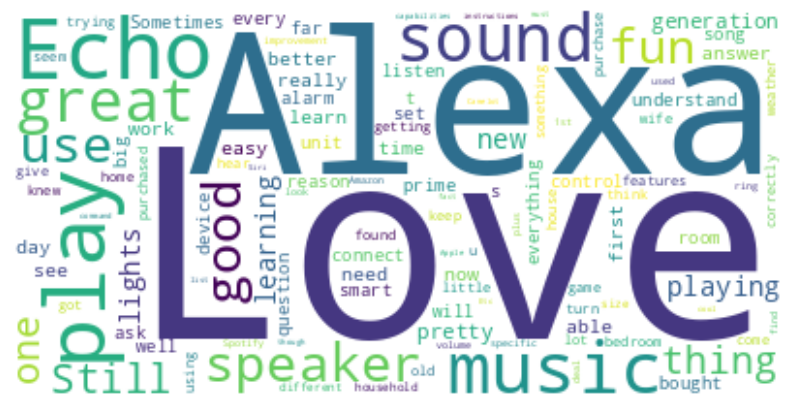

In [ ]:
# Combine all reviews into one large text string
text = " ".join(review for review in df_alexa['verified_reviews'])

# Generate a word cloud from the combined reviews text
wordcloud = WordCloud(collocations=False, background_color='white').generate(text)

# Display the word cloud
plt.figure(figsize=(10, 8))  # Optional: Adjust the figure size to your preference
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")  # Hide the axes
plt.show()

In [ ]:
# Function to calculate sentiment polarity
def get_sentiment(text):
    return TextBlob(text).sentiment.polarity

# Apply sentiment analysis to the reviews column
df_alexa['sentiment'] = df_alexa['verified_reviews'].apply(get_sentiment)

# Create a sentiment label based on polarity scores
df_alexa['sentiment_label'] = df_alexa['sentiment'].apply(
    lambda x: 'Positive' if x > 0 else ('Negative' if x < 0 else 'Neutral')
)

# Check sentiment distribution
print(df_alexa['sentiment_label'].value_counts())

sentiment_label
Positive    44
Negative     3
Neutral      3
Name: count, dtype: int64


In [ ]:
df_alexa

,rating,date,variation,verified_reviews,feedback,demographic,sentiment,sentiment_label
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1,Norway,0.625000,Positive
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1,China,0.875000,Positive
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1,Japan,-0.100000,Negative
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1,Norway,0.350000,Positive
4,5,31-Jul-18,Charcoal Fabric,Music,1,Croatia,0.000000,Neutral
5,5,31-Jul-18,Heather Gray Fabric,I received the echo as a gift. I needed anothe...,1,Croatia,0.294643,Positive
6,3,31-Jul-18,Sandstone Fabric,"Without having a cellphone, I cannot use many ...",1,Japan,0.216667,Positive
7,5,31-Jul-18,Charcoal Fabric,I think this is the 5th one I've purchased. I'...,1,USA,0.200000,Positive
8,5,30-Jul-18,Heather Gray Fabric,looks great,1,Norway,0.800000,Positive
9,5,30-Jul-18,Heather Gray Fabric,Love it! Ive listened to songs I havent hear...,1,Croatia,0.988281,Positive


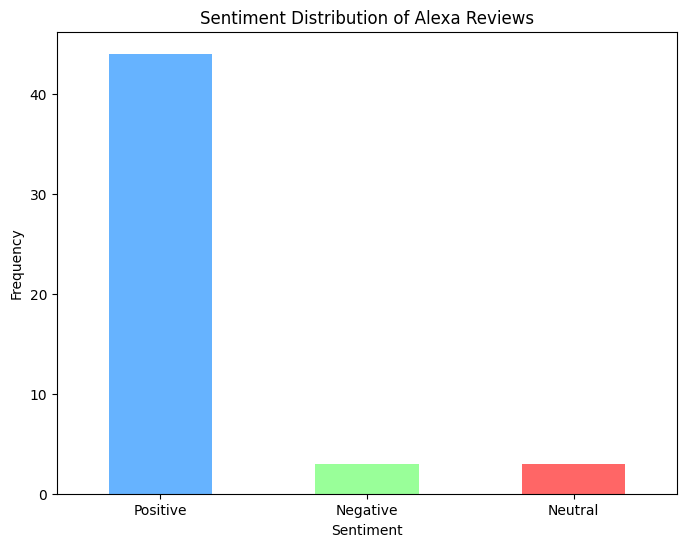

In [ ]:
# Plot the sentiment distribution as a bar chart
sentiment_counts = df_alexa['sentiment_label'].value_counts()

plt.figure(figsize=(8, 6))
sentiment_counts.plot(kind='bar', color=['#66b3ff', '#99ff99', '#ff6666'])
plt.title('Sentiment Distribution of Alexa Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# First Prompt for zero-shot engineering

def classify_reviews(df, prompt, column_name, model="gpt-3.5-turbo", temperature=0.7, max_tokens=150, top_p=1.0):
    # Initialize an empty list to hold results
    classified_data = []
    # Iterate over each row in the DataFrame
    for index, row in df.iterrows():
        # Extract the row text
        row_text = row[column_name]
        response = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": prompt},
                {"role": "user", "content": row_text}
            ],
            temperature=temperature,
            max_tokens=max_tokens,
            top_p=top_p,
        )
        classification = response.choices[0].message.content
        # Append the review and its classification to our results list
        classified_data.append({"column": row_text, "aspects": classification})
    # Create a new DataFrame from our results
    classified_df = pd.DataFrame(classified_data)
    return classified_df


column_name = 'verified_reviews'
prompt = "Extract recurring themes or product aspects from the following customer reviews"
# Call the function and get the classified DataFrame
df_zero1 = classify_reviews(df_alexa,prompt,column_name)
df_zero1

,column,aspects
0,Love my Echo!,The customer expresses satisfaction with their...
1,Loved it!,The product received positive feedback for bei...
2,"Sometimes while playing a game, you can answer...",Recurring themes from the customer reviews are...
3,I have had a lot of fun with this thing. My 4 ...,Recurring themes from the review:\n1. Educatio...
4,Music,- Many customers mentioned that the music sele...
5,I received the echo as a gift. I needed anothe...,- Bluetooth connectivity\n- Easy music playbac...
6,"Without having a cellphone, I cannot use many ...",Themes extracted from the review:\n1. Limited ...
7,I think this is the 5th one I've purchased. I'...,Recurring themes from the review:\n1. Purchasi...
8,looks great,Theme: Visual appeal
9,Love it! Ive listened to songs I havent hear...,"1. Nostalgia\n2. Variety of content (music, ne..."


In [ ]:
# Second Prompt for zero-shot engineering

def classify_reviews(df, prompt, column_name, model="gpt-3.5-turbo", temperature=0.7, max_tokens=150, top_p=1.0):
    # Initialize an empty list to hold results
    classified_data = []
    # Iterate over each row in the DataFrame
    for index, row in df.iterrows():
        # Extract the row text
        row_text = row[column_name]
        response = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": prompt},
                {"role": "user", "content": row_text}
            ],
            temperature=temperature,
            max_tokens=max_tokens,
            top_p=top_p,
        )
        classification = response.choices[0].message.content
        # Append the review and its classification to our results list
        classified_data.append({"column": row_text, "aspects": classification})
    # Create a new DataFrame from our results
    classified_df = pd.DataFrame(classified_data)
    return classified_df

column_name = 'verified_reviews'
prompt = "I have several customer reviews about a product. Your task is to extract common themes or aspects mentioned in the reviews, such as product quality, ease of use, customer service, etc."
# Call the function and get the classified DataFrame
df_zero2  = classify_reviews(df_alexa,prompt,column_name)
df_zero2

,column,aspects
0,Love my Echo!,Theme: Positive feedback
1,Loved it!,This review doesn't provide enough information...
2,"Sometimes while playing a game, you can answer...","From this review, we can extract the following..."
3,I have had a lot of fun with this thing. My 4 ...,Themes mentioned in this review:\n- Educationa...
4,Music,"To provide you with a better analysis, could y..."
5,I received the echo as a gift. I needed anothe...,Themes identified in this review:\n1. Gift rec...
6,"Without having a cellphone, I cannot use many ...","Based on this review, common themes or aspects..."
7,I think this is the 5th one I've purchased. I'...,Themes mentioned in this review:\n- Multiple p...
8,looks great,It seems like the reviewer liked the appearanc...
9,Love it! Ive listened to songs I havent hear...,Themes identified in this review:\n1. Variety ...


In [ ]:
# Third zero shot prompt engineering

def classify_reviews(df, prompt, column_name, model, temperature, max_tokens, top_p):
    # Initialize an empty list to hold results
    classified_data = []
    # Iterate over each row in the DataFrame
    for index, row in df.iterrows():
        # Extract the row text
        row_text = row[column_name]
        response = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": prompt},
                {"role": "user", "content": row_text}
            ],
            temperature=temperature,
            max_tokens=max_tokens,
            top_p=top_p
        )
        classification = response.choices[0].message.content
        # Append the review and its classification to our results list
        classified_data.append({"column": row_text, "aspects": classification})
    # Create a new DataFrame from our results
    classified_df = pd.DataFrame(classified_data)
    return classified_df

column_name = 'verified_reviews'
prompt = "I have several customer reviews of a product. Each review may mention one or more aspects of the product, such as quality, ease of use, performance, design, durability, or customer experience. Your task is to identify all the distinct  aspects mentioned in the review and list them clearly. Ensure all aspects mentioned are included, even if there are multiple and if the review does not mention any aspect write no apsect mentioned."
# Call the function and get the classified DataFrame
df_zero3  = classify_reviews(df_alexa,prompt,column_name,"gpt-3.5-turbo", 0.7, 150, 1.0)
df_zero3

,column,aspects
0,Love my Echo!,Aspects mentioned: \n- No aspect mentioned
1,Loved it!,No aspects mentioned.
2,"Sometimes while playing a game, you can answer...",1. Accuracy issue in game responses\n2. Smart ...
3,I have had a lot of fun with this thing. My 4 ...,Aspects mentioned: \n1. Fun\n2. Educational co...
4,Music,No aspects mentioned.
5,I received the echo as a gift. I needed anothe...,Aspects mentioned:\n- Quality\n- Ease of use
6,"Without having a cellphone, I cannot use many ...",Aspects mentioned in the review:\n1. Ease of u...
7,I think this is the 5th one I've purchased. I'...,Aspects mentioned:\n1. Features\n2. Playing mu...
8,looks great,Aspects mentioned: design
9,Love it! Ive listened to songs I havent hear...,Aspects mentioned:\n1. Entertainment (listenin...


In [ ]:
# First Few Shot Prompt for Aspect Detection
# Start with examples not direclty related to out dataset
# The parameters entails a more diverse response as the examples are not related to our dataset therefore we want the model to be more creative
def classify_reviews_with_few_shot_examples(df, column_name, prompt, few_shot_examples, temperature, max_tokens, top_p):
# Initialize an empty list to hold our results
    classified_data = []
# Iterate over each row in the DataFrame
    for index, row in df.iterrows():
# Extract the review text
        row_val = row[column_name]
# Create the prompt with the few-shot examples and the current review
        full_prompt = prompt + "\n\n".join(few_shot_examples) + f"\n\n{row_val}"
# Again here, you can change the content to experiment around
        response = client.chat.completions.create(model="gpt-3.5-turbo", messages=[
        {"role": "system", "content": "Classify the text based on the provided examples"},
        {"role": "user", "content": full_prompt}
        ], temperature=temperature,
            max_tokens=max_tokens,
            top_p=top_p)
        classification = response.choices[0].message.content
# Append the review and its classification to our results list
        classified_data.append({"column": row_val, "classification": classification})
    classified_df = pd.DataFrame(classified_data)
    return classified_df

prompt = "Extract the key aspects mentioned in the following reviews. Each review contains opinions about a product or service."
few_shot_examples = """
Review 1: "The food was delicious, but the service was slow."
Aspects: Food, Service

Review 2: "I loved the vibrant colors of the painting, but the frame felt cheap."
Aspects: Colors, Frame quality

Review 3: "The movie's plot was engaging, though the soundtrack was forgettable."
Aspects: Plot, Soundtrack

Review 4: "The phone's battery lasts long, but the screen resolution is subpar."
Aspects: Battery life, Screen resolution
"""
# Following is an example of how to use the function, replace the variables, prompt and the few shot examples based on your task
df_few1 = classify_reviews_with_few_shot_examples(df_alexa,column_name, prompt, few_shot_examples, 0.7, 150, 1.0)

df_few1

,column,classification
0,Love my Echo!,"Food, Service\nColors, Frame quality\nPlot, So..."
1,Loved it!,"Food, Service, Colors, Frame quality, Plot, So..."
2,"Sometimes while playing a game, you can answer...","Food, Service, Colors, Frame quality, Plot, So..."
3,I have had a lot of fun with this thing. My 4 ...,"Food Quality, Service Quality, Color Vibrancy,..."
4,Music,"Food, Service, Colors, Frame quality, Plot, So..."
5,I received the echo as a gift. I needed anothe...,Aspects mentioned in the reviews:\n\n1. Review...
6,"Without having a cellphone, I cannot use many ...","Food, service, colors, frame quality, plot, so..."
7,I think this is the 5th one I've purchased. I'...,"Food, Service, Colors, Frame quality, Plot, So..."
8,looks great,"Food, Service, Colors, Frame quality, Plot, So..."
9,Love it! Ive listened to songs I havent hear...,Aspect: Functionality


In [ ]:
# Second few shot prompt for aspect detection
# Include implict and explicit aspects
def classify_reviews_with_few_shot_examples(df, column_name, prompt, few_shot_examples, temperature, max_tokens, top_p):
# Initialize an empty list to hold our results
    classified_data = []
# Iterate over each row in the DataFrame
    for index, row in df.iterrows():
# Extract the review text
        row_val = row[column_name]
# Create the prompt with the few-shot examples and the current review
        full_prompt = prompt + "\n\n".join(few_shot_examples) + f"\n\n{row_val}"
# Again here, you can change the content to experiment around
        response = client.chat.completions.create(model="gpt-3.5-turbo", messages=[
        {"role": "system", "content": "Classify the text based on the provided examples"},
        {"role": "user", "content": full_prompt}
        ], temperature=temperature,
            max_tokens=max_tokens,
            top_p=top_p)
        classification = response.choices[0].message.content
# Append the review and its classification to our results list
        classified_data.append({"column": row_val, "classification": classification})
    classified_df = pd.DataFrame(classified_data)
    return classified_df
prompt = "Analyze the following customer reviews and extract the product aspects mentioned. If multiple aspects are mentioned, list them as concise phrases separated by commas. If no aspect is mentioned in the review, respond:No aspect mentioned."
few_shot_examples = """Extract the key product aspects mentioned in the following customer reviews. List the aspects as concise phrases.

Review 1: "The battery life is fantastic, lasting me an entire day with heavy usage."
Aspects: Battery life

Review 2: "I love the design of the laptop—it’s sleek and modern. However, the keyboard is uncomfortable for long typing sessions."
Aspects: Design, Keyboard comfort

Review 3: "The display is sharp and vibrant, but the screen is very reflective, which makes it hard to use outdoors."
Aspects: Display quality, Screen reflectiveness

Review 4: "The processor is really fast, allowing for smooth multitasking, though the fan gets quite loud under heavy loads."
Aspects: Processor speed, Fan noise

Review 5: "The sound quality is impressive, but the microphone picks up too much background noise during calls."
Aspects: Sound quality, Microphone performance

Now extract the aspects from this review:
Review: "The build quality feels premium, and the touchpad is very responsive. However, the webcam is disappointing in low light."
Aspects:"""


# Following is an example of how to use the function, replace the variables, prompt and the few shot examples based on your task
df_few2 = classify_reviews_with_few_shot_examples(df_alexa,column_name, prompt, few_shot_examples, 0.7, 150, 1.0)
df_few2


,column,classification
0,Love my Echo!,"Aspect: Battery life\nAspect: Design, Keyboard..."
1,Loved it!,Aspect mentioned: Battery life\n\nAspect menti...
2,"Sometimes while playing a game, you can answer...",Aspect:\n- Build quality\n- Touchpad responsiv...
3,I have had a lot of fun with this thing. My 4 ...,"Aspect: Build quality, Touchpad responsiveness..."
4,Music,"Aspect: Battery life\n\nAspect: Design, Keyboa..."
5,I received the echo as a gift. I needed anothe...,"Aspect mentioned in the review: Build quality,..."
6,"Without having a cellphone, I cannot use many ...",Aspect:\n- Build quality\n- Touchpad responsiv...
7,I think this is the 5th one I've purchased. I'...,"Aspects:\n- Battery life (Review 1)\n- Design,..."
8,looks great,"Review 1: Battery life\nReview 2: Design, Keyb..."
9,Love it! Ive listened to songs I havent hear...,"Aspect: Build quality, Touchpad responsiveness..."


In [ ]:
# Third few shot prompt
# Put distinct examples, where no aspect is mentioned, reviews that maybe mention multiple aspects and hard reviews to identify.
def classify_reviews_with_few_shot_examples(df, column_name, prompt, few_shot_examples, temperature, max_tokens, top_p):
# Initialize an empty list to hold our results
    classified_data = []
# Iterate over each row in the DataFrame
    for index, row in df.iterrows():
# Extract the review text
        row_val = row[column_name]
# Create the prompt with the few-shot examples and the current review
        full_prompt = prompt + "\n\n".join(few_shot_examples) + f"\n\n{row_val}"
# Again here, you can change the content to experiment around
        response = client.chat.completions.create(model="gpt-3.5-turbo", messages=[
        {"role": "system", "content": "Classify the text based on the provided examples"},
        {"role": "user", "content": full_prompt}
        ], temperature=temperature,
            max_tokens=max_tokens,
            top_p=top_p)
        classification = response.choices[0].message.content
# Append the review and its classification to our results list
        classified_data.append({"column": row_val, "classification": classification})
    classified_df = pd.DataFrame(classified_data)
    return classified_df
# Following is an example of how to use the function, replace the variables, prompt and the few shot examples based on your task
# df was not defined, changing it to df_alexa assuming this was your intent
df_few3 = classify_reviews_with_few_shot_examples(df_alexa,column_name, prompt, few_shot_examples, 0.7, 150, 1.0)
[
"text1: category1",
"text2: category2",
"text3: category3"
]

['text1: category1', 'text2: category2', 'text3: category3']

In [ ]:
# Define a few-shot prompt for sentiment classification
few_shot_prompt = """
Q: 'I love this product, it works perfectly!'
A: Positive

Q: 'It stopped working after a week.'
A: Negative

Q: 'The product is okay, but I expected more.'
A: Neutral

Q: 'I am very satisfied with the performance of the item.'
"""

response = client.chat.completions.create(
    model="gpt-3.5-turbo",
    messages=[
        {"role": "system", "content": "Classify the sentiment of the review based on the examples."},
        {"role": "user", "content": few_shot_prompt}
    ]
)

classification = response.choices[0].message.content
print(classification)


Positive


In [ ]:
# Define a few-shot prompt for sentiment classification
few_shot_prompt = """
Q: 'I love this product, it works perfectly!'
A: Positive

Q: 'It stopped working after a week.'
A: Negative

Q: 'The product is okay, but I expected more.'
A: Neutral

Q: 'Without having a cellphone, I cannot use many of her features. I have an iPad but do not see that of any use.  It IS a great alarm.  If u r almost deaf, you can hear her alarm in the bedroom from out in the living room, so that is reason enough to keep her.It is fun to ask random questions to hear her response.  She does not seem to be very smartbon politics yet.'
"""

response = client.chat.completions.create(
    model="gpt-3.5-turbo",
    messages=[
        {"role": "system", "content": "Classify the sentiment of the review based on the examples."},
        {"role": "user", "content": few_shot_prompt}
    ]
)

classification = response.choices[0].message.content
print(classification)

Neutral


In [ ]:
# Define a few-shot prompt for sentiment classification
few_shot_prompt = """
Q: 'I love this product, it works perfectly!'
A: Positive

Q: 'It stopped working after a week.'
A: Negative

Q: 'The product is okay, but I expected more.'
A: Neutral

Q: 'No different than Apple. To play a specific list of music you must have an Amazon of Spotify “plus/prime/etc” account.  So you must pay to play “your” music.  3 stars for that reason.  Everything else is ???? .'
"""

response = client.chat.completions.create(
    model="gpt-3.5-turbo",
    messages=[
        {"role": "system", "content": "Classify the sentiment of the review based on the examples."},
        {"role": "user", "content": few_shot_prompt}
    ]
)

classification = response.choices[0].message.content
print(classification)

Neutral


In [ ]:
# Chain-of-thought example to extract features influencing a purchase
chain_of_thought_prompt = """
Review: 'I bought this product because the price was great, and the design was just what I was looking for.'
Factors influencing purchase: Price and design
"""

response = client.chat.completions.create(
    model="gpt-3.5-turbo",
    messages=[
        {"role": "system", "content": "Extract the factors that influenced the purchase decision."},
        {"role": "user", "content": chain_of_thought_prompt}
    ]
)

extracted_factors = response.choices[0].message.content
print(extracted_factors)

Factors influencing purchase decision: Price and design.


In [ ]:
# Chain-of-thought example to extract features influencing a purchase
chain_of_thought_prompt = """
Review: 'I bought this to compare the speaker quality to our first generation speaker and i like the sound better.  I will ship this to my daughter though because I like the fact that my first generation has a chargeable base that we bought which keeps it more mobile and she needs a better sound than what she has now.'
Factors influencing purchase: Quality of Sound and Mobility
"""

response = client.chat.completions.create(
    model="gpt-3.5-turbo",
    messages=[
        {"role": "system", "content": "Extract the factors that influenced the purchase decision."},
        {"role": "user", "content": chain_of_thought_prompt}
    ]
)

extracted_factors = response.choices[0].message.content
print(extracted_factors)

Factors that influenced the purchase decision:
1. Quality of Sound: The customer found the sound quality of the new speaker better than their first generation speaker, which influenced their decision to purchase it.
2. Mobility: Although the customer preferred the sound of the new speaker, they decided to ship it to their daughter because their first generation speaker had a chargeable base, making it more mobile. The ability to be more portable and versatile was a significant factor in the purchase decision.


In [ ]:
# Example prompt and GPT-3 generation (You can use your own prompt for summarization/classification)
def generate_gpt_output(review_text):
    prompt = f"Summarize the following review: {review_text}"

    response = client.chat.completions.create(
        model="gpt-3.5-turbo",
        messages=[
            {"role": "system", "content": "Summarize the review in one sentence."},
            {"role": "user", "content": prompt}
        ]
    )

    return response.choices[0].message.content

# Apply the function to generate GPT-3 output for each review and store it in the 'generated' column
df_alexa['generated'] = df_alexa['verified_reviews'].apply(generate_gpt_output)

In [ ]:
# Create an 'actual' column with sentiment labels or actual summaries if not already present
df_alexa['actual'] = df_alexa['sentiment_label']

In [ ]:
from fuzzywuzzy import fuzz

# Assuming 'generated' column has GPT-3 output and 'actual' column has actual sentiment or summary
df_alexa['similarity'] = df_alexa.apply(lambda x: fuzz.partial_ratio(x['generated'], x['actual']), axis=1)

# Filter results with a similarity score above 50
df_alexa_filtered = df_alexa[df_alexa['similarity'] >= 50]
print(df_alexa_filtered)

    rating       date             variation  \
10       5  30-Jul-18      Charcoal Fabric    
11       5  30-Jul-18      Charcoal Fabric    
13       5  30-Jul-18      Charcoal Fabric    
17       5  30-Jul-18  Heather Gray Fabric    
22       4  30-Jul-18  Heather Gray Fabric    
23       5  30-Jul-18      Charcoal Fabric    
25       5  30-Jul-18     Sandstone Fabric    
27       5  30-Jul-18      Charcoal Fabric    
29       5  30-Jul-18      Charcoal Fabric    
34       5  30-Jul-18      Charcoal Fabric    
36       5  30-Jul-18     Sandstone Fabric    
42       4  30-Jul-18      Charcoal Fabric    
44       5  30-Jul-18     Sandstone Fabric    
48       5  30-Jul-18  Heather Gray Fabric    

                                     verified_reviews  feedback  demographic  \
10  I sent it to my 85 year old Dad, and he talks ...         1        India   
11  I love it! Learning knew things with it eveyda...         1  Netherlands   
13                                 Love, Love, Love!! 

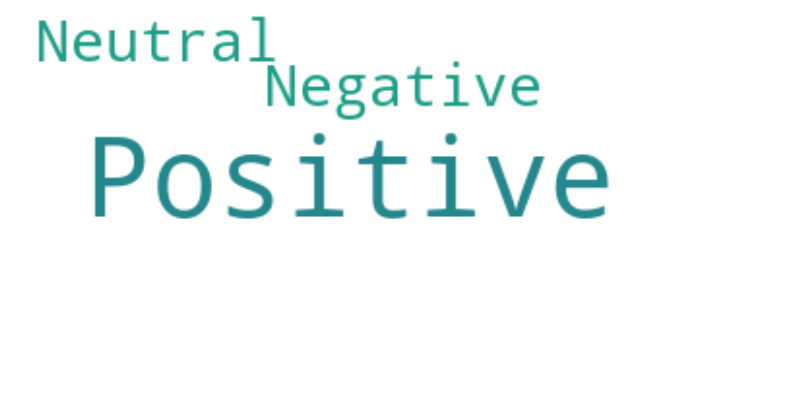

In [ ]:
# Creating word cloud from sentiment labels
text = " ".join(sentiment for sentiment in df_alexa['sentiment_label'])

wordcloud = WordCloud(collocations=False, background_color='white').generate(text)

plt.figure(figsize=(10, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

Filtered Reviews with High Similarity:     rating       date             variation  \
10       5  30-Jul-18      Charcoal Fabric    
11       5  30-Jul-18      Charcoal Fabric    
13       5  30-Jul-18      Charcoal Fabric    
17       5  30-Jul-18  Heather Gray Fabric    
22       4  30-Jul-18  Heather Gray Fabric    
23       5  30-Jul-18      Charcoal Fabric    
25       5  30-Jul-18     Sandstone Fabric    
27       5  30-Jul-18      Charcoal Fabric    
29       5  30-Jul-18      Charcoal Fabric    
34       5  30-Jul-18      Charcoal Fabric    
36       5  30-Jul-18     Sandstone Fabric    
42       4  30-Jul-18      Charcoal Fabric    
44       5  30-Jul-18     Sandstone Fabric    
48       5  30-Jul-18  Heather Gray Fabric    

                                     verified_reviews  feedback  demographic  \
10  I sent it to my 85 year old Dad, and he talks ...         1        India   
11  I love it! Learning knew things with it eveyda...         1  Netherlands   
13             

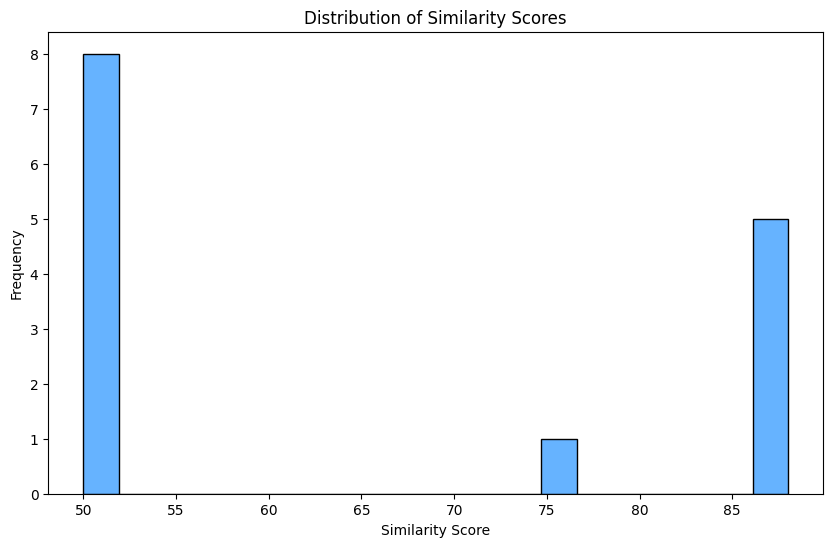

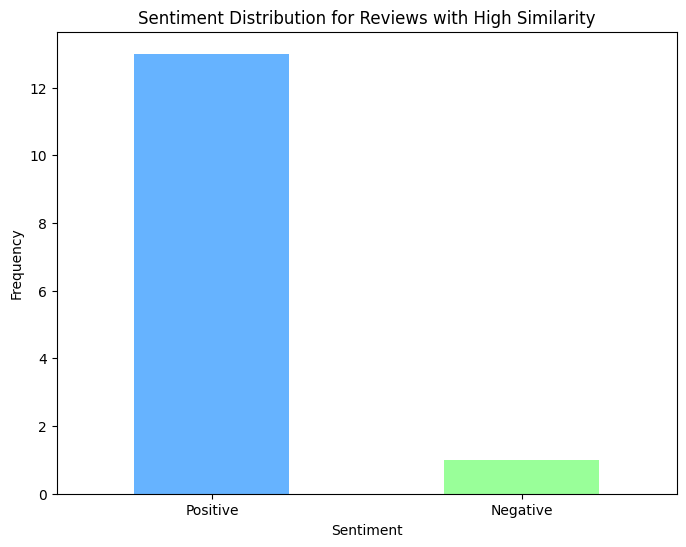

In [ ]:
# Example: Apply fuzzywuzzy to compare GPT-3 output with sentiment labels
df_alexa['similarity'] = df_alexa.apply(lambda x: fuzz.partial_ratio(x['generated'], x['sentiment_label']), axis=1)

# Filter results with a similarity score above 50
df_alexa_filtered = df_alexa[df_alexa['similarity'] >= 50]
print("Filtered Reviews with High Similarity:", df_alexa_filtered)

# Visualizing the similarity distribution
plt.figure(figsize=(10, 6))
df_alexa_filtered['similarity'].plot(kind='hist', bins=20, color='#66b3ff', edgecolor='black')
plt.title('Distribution of Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.show()

# Optional: Visualizing the sentiment distribution of filtered reviews
sentiment_counts_filtered = df_alexa_filtered['sentiment_label'].value_counts()
plt.figure(figsize=(8, 6))
sentiment_counts_filtered.plot(kind='bar', color=['#66b3ff', '#99ff99', '#ff6666'])
plt.title('Sentiment Distribution for Reviews with High Similarity')
plt.xlabel('Sentiment')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Print some examples of high similarity
print(df_alexa_filtered[['verified_reviews', 'generated', 'similarity']].head(10))  # Adjust the number if needed

                                     verified_reviews  \
10  I sent it to my 85 year old Dad, and he talks ...   
11  I love it! Learning knew things with it eveyda...   
13                                 Love, Love, Love!!   
17  We have only been using Alexa for a couple of ...   
22  Have only had it set up for a few days. Still ...   
23  I love it. It plays my sleep sounds immediatel...   
25                                    Amazing product   
27                          Sounds great!! Love them!   
29                            Just like the other one   
34                            This device is awesome!   

                                            generated  similarity  
10  The reviewer sent the product to their 85-year...          50  
11  The reviewer loves the product, finds it easy ...          50  
13  The reviewer is very enthusiastic and expresse...          88  
17  The reviewer is enjoying their new Alexa devic...          50  
22  The reviewer is pleased with

In [ ]:
prompt = "Please summarize the following review, focusing on product features and customer experience."

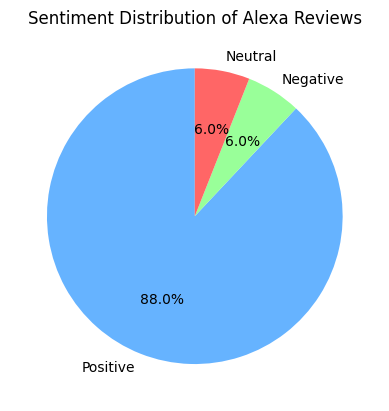

In [ ]:
# Sentiment distribution
sentiment_counts = df_alexa['sentiment_label'].value_counts()
sentiment_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#99ff99', '#ff6666'])
plt.title('Sentiment Distribution of Alexa Reviews')
plt.ylabel('')
plt.show()

In [ ]:
def extract_themes(review_text):
    prompt = f"Identify common themes in this review: {review_text}"
    response = client.chat.completions.create(
        model="gpt-3.5-turbo",
        messages=[
            {"role": "system", "content": "Extract themes from the customer review."},
            {"role": "user", "content": prompt}
        ]
    )
    return response.choices[0].message.content

df_alexa['themes'] = df_alexa['verified_reviews'].apply(extract_themes)

In [ ]:
# Check if there's a relationship between rating and sentiment
df_alexa['rating'] = df_alexa['rating'].astype(int)
df_alexa['rating_sentiment_correlation'] = df_alexa['rating'].corr(df_alexa['sentiment'])
print(df_alexa[['rating', 'sentiment']].corr())

             rating  sentiment
rating     1.000000   0.278388
sentiment  0.278388   1.000000


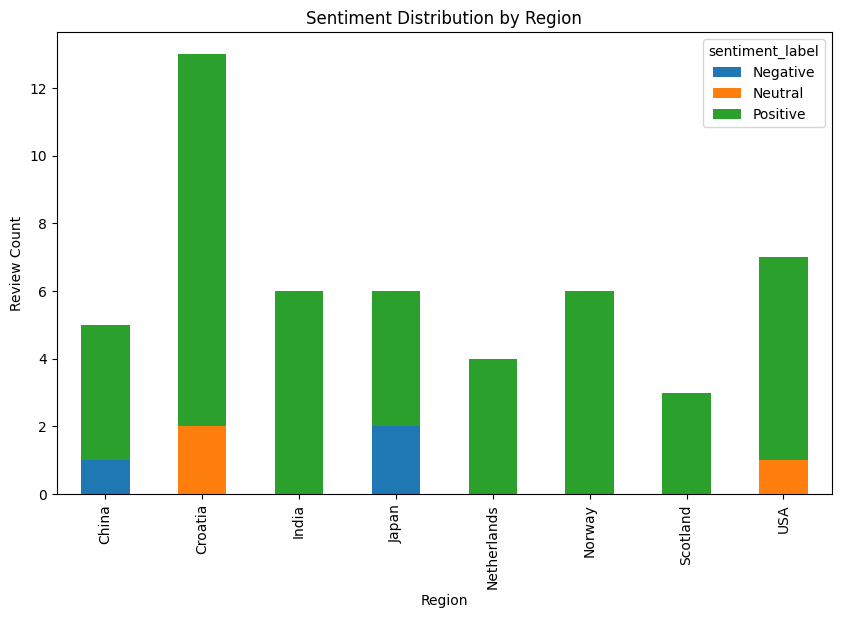

In [ ]:
# Geographic sentiment analysis
sentiment_by_country = df_alexa.groupby('demographic')['sentiment_label'].value_counts().unstack()
sentiment_by_country.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Sentiment Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Review Count')
plt.xticks(rotation=90)
plt.show()

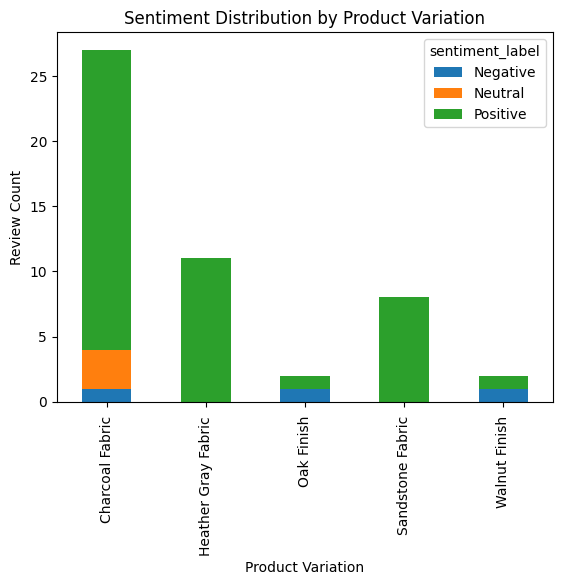

In [ ]:
# Sentiment analysis based on product variation
df_alexa.groupby('variation')['sentiment_label'].value_counts().unstack().plot(kind='bar', stacked=True)
plt.title('Sentiment Distribution by Product Variation')
plt.xlabel('Product Variation')
plt.ylabel('Review Count')
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Apply fuzzy matching to compare generated text with actual sentiment labels
df_alexa['similarity'] = df_alexa.apply(lambda x: fuzz.partial_ratio(x['generated'], x['sentiment_label']), axis=1)

# Filter results with high similarity
df_alexa_filtered = df_alexa[df_alexa['similarity'] >= 50]
print(df_alexa_filtered[['verified_reviews', 'generated', 'sentiment_label', 'similarity']].head())

                                     verified_reviews  \
10  I sent it to my 85 year old Dad, and he talks ...   
11  I love it! Learning knew things with it eveyda...   
13                                 Love, Love, Love!!   
17  We have only been using Alexa for a couple of ...   
22  Have only had it set up for a few days. Still ...   

                                            generated sentiment_label  \
10  The reviewer sent the product to their 85-year...        Positive   
11  The reviewer loves the product, finds it easy ...        Positive   
13  The reviewer is very enthusiastic and expresse...        Positive   
17  The reviewer is enjoying their new Alexa devic...        Positive   
22  The reviewer is pleased with the smart home de...        Positive   

    similarity  
10          50  
11          50  
13          88  
17          50  
22          50  


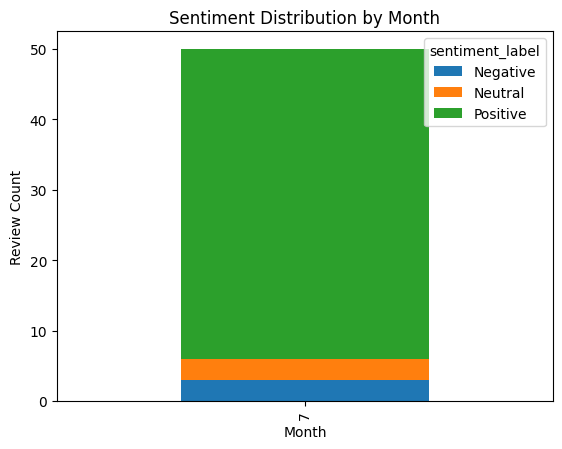

In [ ]:
df_alexa['date'] = pd.to_datetime(df_alexa['date'], format='%d-%b-%y')
df_alexa['month'] = df_alexa['date'].dt.month
df_alexa.groupby('month')['sentiment_label'].value_counts().unstack().plot(kind='bar', stacked=True)
plt.title('Sentiment Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Review Count')
plt.show()

In [ ]:
# Count the frequency of feature requests
# Check if 'feature_request' column exists before accessing it
if 'feature_request' in df_alexa.columns:
    feature_counts = df_alexa['feature_request'].value_counts()

    # Plot a bar chart of feature requests
    feature_counts.plot(kind='bar', figsize=(10, 6), color='#66b3ff')
    plt.title('Frequency of Feature Requests in Alexa Reviews')
    plt.xlabel('Feature Request')
    plt.ylabel('Frequency')
    plt.xticks(rotation=90)
    plt.show()
else:
    print("Column 'feature_request' not found in DataFrame.")

Column 'feature_request' not found in DataFrame.


In [ ]:
# Check if there's a relationship between rating and sentiment
df_alexa['rating'] = df_alexa['rating'].astype(int)
df_alexa['rating_sentiment_correlation'] = df_alexa['rating'].corr(df_alexa['sentiment'])
print(f"Correlation between Rating and Sentiment: {df_alexa['rating_sentiment_correlation']}")

Correlation between Rating and Sentiment: 0     0.278388
1     0.278388
2     0.278388
3     0.278388
4     0.278388
5     0.278388
6     0.278388
7     0.278388
8     0.278388
9     0.278388
10    0.278388
11    0.278388
12    0.278388
13    0.278388
14    0.278388
15    0.278388
16    0.278388
17    0.278388
18    0.278388
19    0.278388
20    0.278388
21    0.278388
22    0.278388
23    0.278388
24    0.278388
25    0.278388
26    0.278388
27    0.278388
28    0.278388
29    0.278388
30    0.278388
31    0.278388
32    0.278388
33    0.278388
34    0.278388
35    0.278388
36    0.278388
37    0.278388
38    0.278388
39    0.278388
40    0.278388
41    0.278388
42    0.278388
43    0.278388
44    0.278388
45    0.278388
46    0.278388
47    0.278388
48    0.278388
49    0.278388
Name: rating_sentiment_correlation, dtype: float64


More Details

In [ ]:
from transformers import pipeline

# Assuming `df_alexa` contains the full dataset
# Initialize amazon_alexa_top50
amazon_alexa_top50 = df_alexa.head(50)  # Get the top 50 reviews

# Extract the first 50 reviews from the 'verified_reviews' column
reviews = amazon_alexa_top50['verified_reviews'].fillna('').tolist()[:50]

# Load the GPT-2 model
generator = pipeline('text-generation', model='gpt2')

# Chain-of-thought prompting for feature requests
# Chain-of-thought prompting for feature requests
for i, review in enumerate(reviews):
    prompt = f"""
    Q: "{review}"
    A: Analyze this review for suggestions or feature requests. If no specific request is mentioned, respond with 'No request mentioned.'
    """
    output = generator(prompt, max_new_tokens=50, temperature=0.7, top_p=0.9)
    print(f"Review {i+1}: {output[0]['generated_text']}")


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


Review 1: 
    Q: "Love my Echo!"
    A: Analyze this review for suggestions or feature requests. If no specific request is mentioned, respond with 'No request mentioned.'
     Q: "It's not a good song to play while you're asleep."
    A: When you're asleep, you're singing to yourself. It's important to have your voice heard.
     Q: "


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


Review 2: 
    Q: "Loved it!"
    A: Analyze this review for suggestions or feature requests. If no specific request is mentioned, respond with 'No request mentioned.'
     Q: "Loved it!"    A: If you liked it, please share it on Facebook, Twitter, or other social media. If you don't like it, you can leave a comment on the review.
   


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


...

Review 47: 
    Q: "It's like Siri, in fact, Siri answers more accurately then Alexa.  I don't see a real need for it in my household, though it was a good bargain on prime day deals."
    A: Analyze this review for suggestions or feature requests. If no specific request is mentioned, respond with 'No request mentioned.'
     Q: "It has a bit of a 'no' button, but not too much.  I don't really care.  I just like to do stuff, and it's a nice touch."
    A: "I like


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


Review 48: 
    Q: "Love my Echo. Still learning how every thing works but having tons of fun."
    A: Analyze this review for suggestions or feature requests. If no specific request is mentioned, respond with 'No request mentioned.'
     A: Try not to miss a post or comment. Don't have time to make a post? Sign up to get notified when new posts are posted.
     A: When you're done with your review, you'll be able


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


Review 49: 
    Q: "I love you so much"
    A: Analyze this review for suggestions or feature requests. If no specific request is mentioned, respond with 'No request mentioned.'
     Q: "I am so glad you like me"    A: Try it out for yourself or check out our other reviews here. If you're just starting out, make sure you have the right background.
     Q
Review 50: 
    Q: "No different than Apple. To play a specific list of music you must have an Amazon of Spotify plus/prime/etc account.  So you must pay to play your music.  3 stars for that reason.  Everything else is ???? ."
    A: Analyze this review for suggestions or feature requests. If no specific request is mentioned, respond with 'No request mentioned.'
     A: If there are no specific requests mentioned, ask for a comment.
     A: If there are specific requests mentioned, ask for a comment.
     A: If there are specific requests mentioned, ask for


In [ ]:
amazon_alexa_top50 = df_alexa.head(50)  # Take the first 50 rows

In [ ]:
print(df_alexa.columns)

Index(['rating', 'date', 'variation', 'verified_reviews', 'feedback',
       'demographic', 'sentiment', 'sentiment_label', 'generated', 'actual',
       'similarity', 'themes', 'rating_sentiment_correlation', 'month'],
      dtype='object')


In [ ]:
reviews = amazon_alexa_top50['verified_reviews'].fillna('').tolist()[:50]

In [ ]:
print(reviews)

['Love my Echo!', 'Loved it!', 'Sometimes while playing a game, you can answer a question correctly but Alexa says you got it wrong and answers the same as you.  I like being able to turn lights on and off while away from home.', 'I have had a lot of fun with this thing. My 4 yr old learns about dinosaurs, i control the lights and play games like categories. Has nice sound when playing music as well.', 'Music', 'I received the echo as a gift. I needed another Bluetooth or something to play music easily accessible, and found this smart speaker. Can\x92t wait to see what else it can do.', 'Without having a cellphone, I cannot use many of her features. I have an iPad but do not see that of any use.  It IS a great alarm.  If u r almost deaf, you can hear her alarm in the bedroom from out in the living room, so that is reason enough to keep her.It is fun to ask random questions to hear her response.  She does not seem to be very smartbon politics yet.', "I think this is the 5th one I've pur

In [ ]:
import pandas as pd

# Load the dataset (replace with actual file path)
amazon_alexa = pd.read_csv('amazon_alexa.tsv', sep='\t', encoding='latin1')

# Use top 50 rows for analysis
amazon_alexa_top50 = amazon_alexa.head(50)

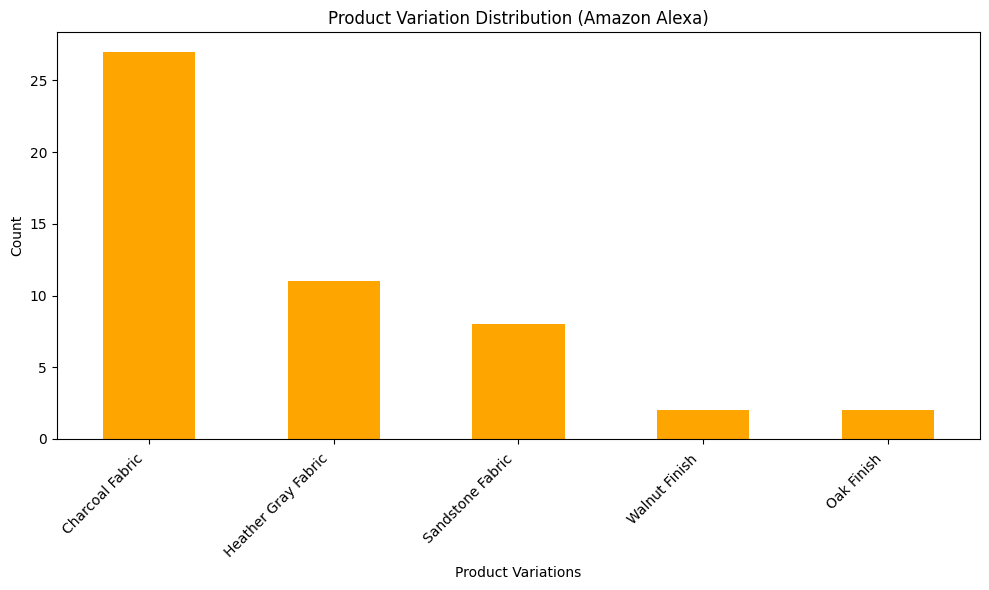

In [ ]:
# Product Variation Analysis
variation_counts = amazon_alexa_top50['variation'].value_counts()

# Bar Chart for Product Variations
plt.figure(figsize=(10, 6))
variation_counts.plot(kind='bar', color='orange')
plt.title('Product Variation Distribution (Amazon Alexa)')
plt.xlabel('Product Variations')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

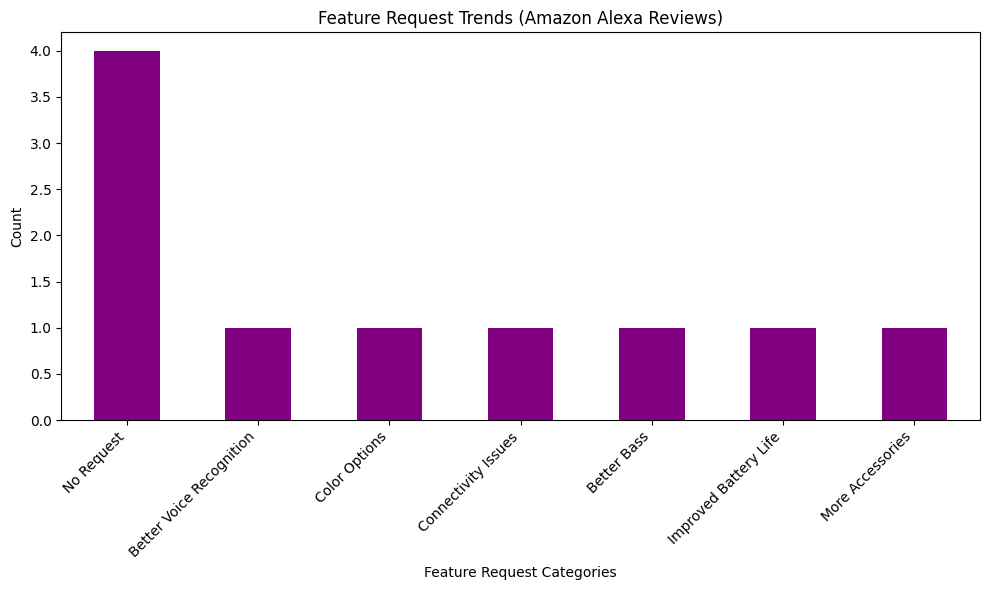

In [ ]:
# Manually simulate feature request categories from earlier review analysis
feature_requests = [
    "Better Voice Recognition",
    "Color Options",
    "No Request",
    "Connectivity Issues",
    "No Request",
    "Better Bass",
    "No Request",
    "Improved Battery Life",
    "No Request",
    "More Accessories"
]

# Count occurrences of each category
feature_request_counts = pd.Series(feature_requests).value_counts()

# Bar Chart for Feature Request Trends
plt.figure(figsize=(10, 6))
feature_request_counts.plot(kind='bar', color='purple')
plt.title('Feature Request Trends (Amazon Alexa Reviews)')
plt.xlabel('Feature Request Categories')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

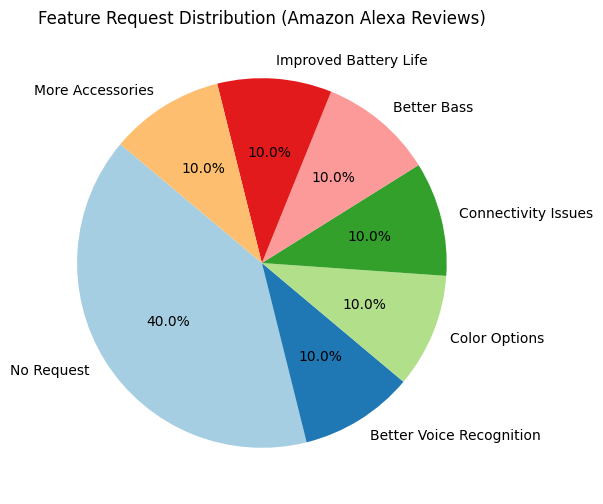

In [ ]:
# Pie Chart for Feature Request Trends
plt.figure(figsize=(8, 6))
plt.pie(
    feature_request_counts,
    labels=feature_request_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Paired.colors
)
plt.title('Feature Request Distribution (Amazon Alexa Reviews)')
plt.show()

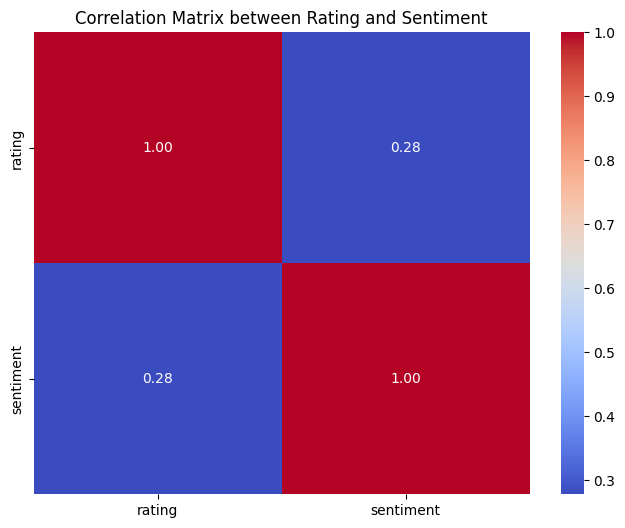

In [ ]:
correlation = df_alexa[['rating', 'sentiment']].corr()
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix between Rating and Sentiment')
plt.show()

In [ ]:
# Save outputs in a file
with open("prompt_results.txt", "w") as file:
    file.write("Generated Results:\n")
    file.write(output[0]['generated_text'])